# Stock Triple-Barrier Classification · 01 Data Understanding

# Aim, Objective, and Motivation
- **Aim:** <u>understand</u> how daily stock prices behave before trying to predict anything.
- **Objective:** check data health, compare prices with returns (stationarity, fat tails, volatility clustering)
  and show why my first version's high R² was misleading.
- **Motivation:** my first version (RNN / LSTM / GRU) predicted the **scaled closing price** and reached R² ≈ 0.99.
  This project replaces that target with **triple-barrier labels**: will a trade starting today hit its
  take-profit, its stop-loss, or run out of time?

**Data:** daily OHLCV from Yahoo Finance via `yfinance` (split and dividend adjusted), 2010-01-01 to 2026-11-11,
for the 14 stocks of my first version plus `SPY` (S&P 500 ETF) as market context.

# Outlines
1. Download prices
2. Data health
3. Prices over time
4. Returns: distribution and fat tails
5. Stationarity: price vs return
6. Autocorrelation and volatility clustering
7. The price-level trap
    - 7.1 Naive "tomorrow = today" forecast
    - 7.2 Scaling before splitting
8. Summary & decisions

<!-- objective -->
## Objective

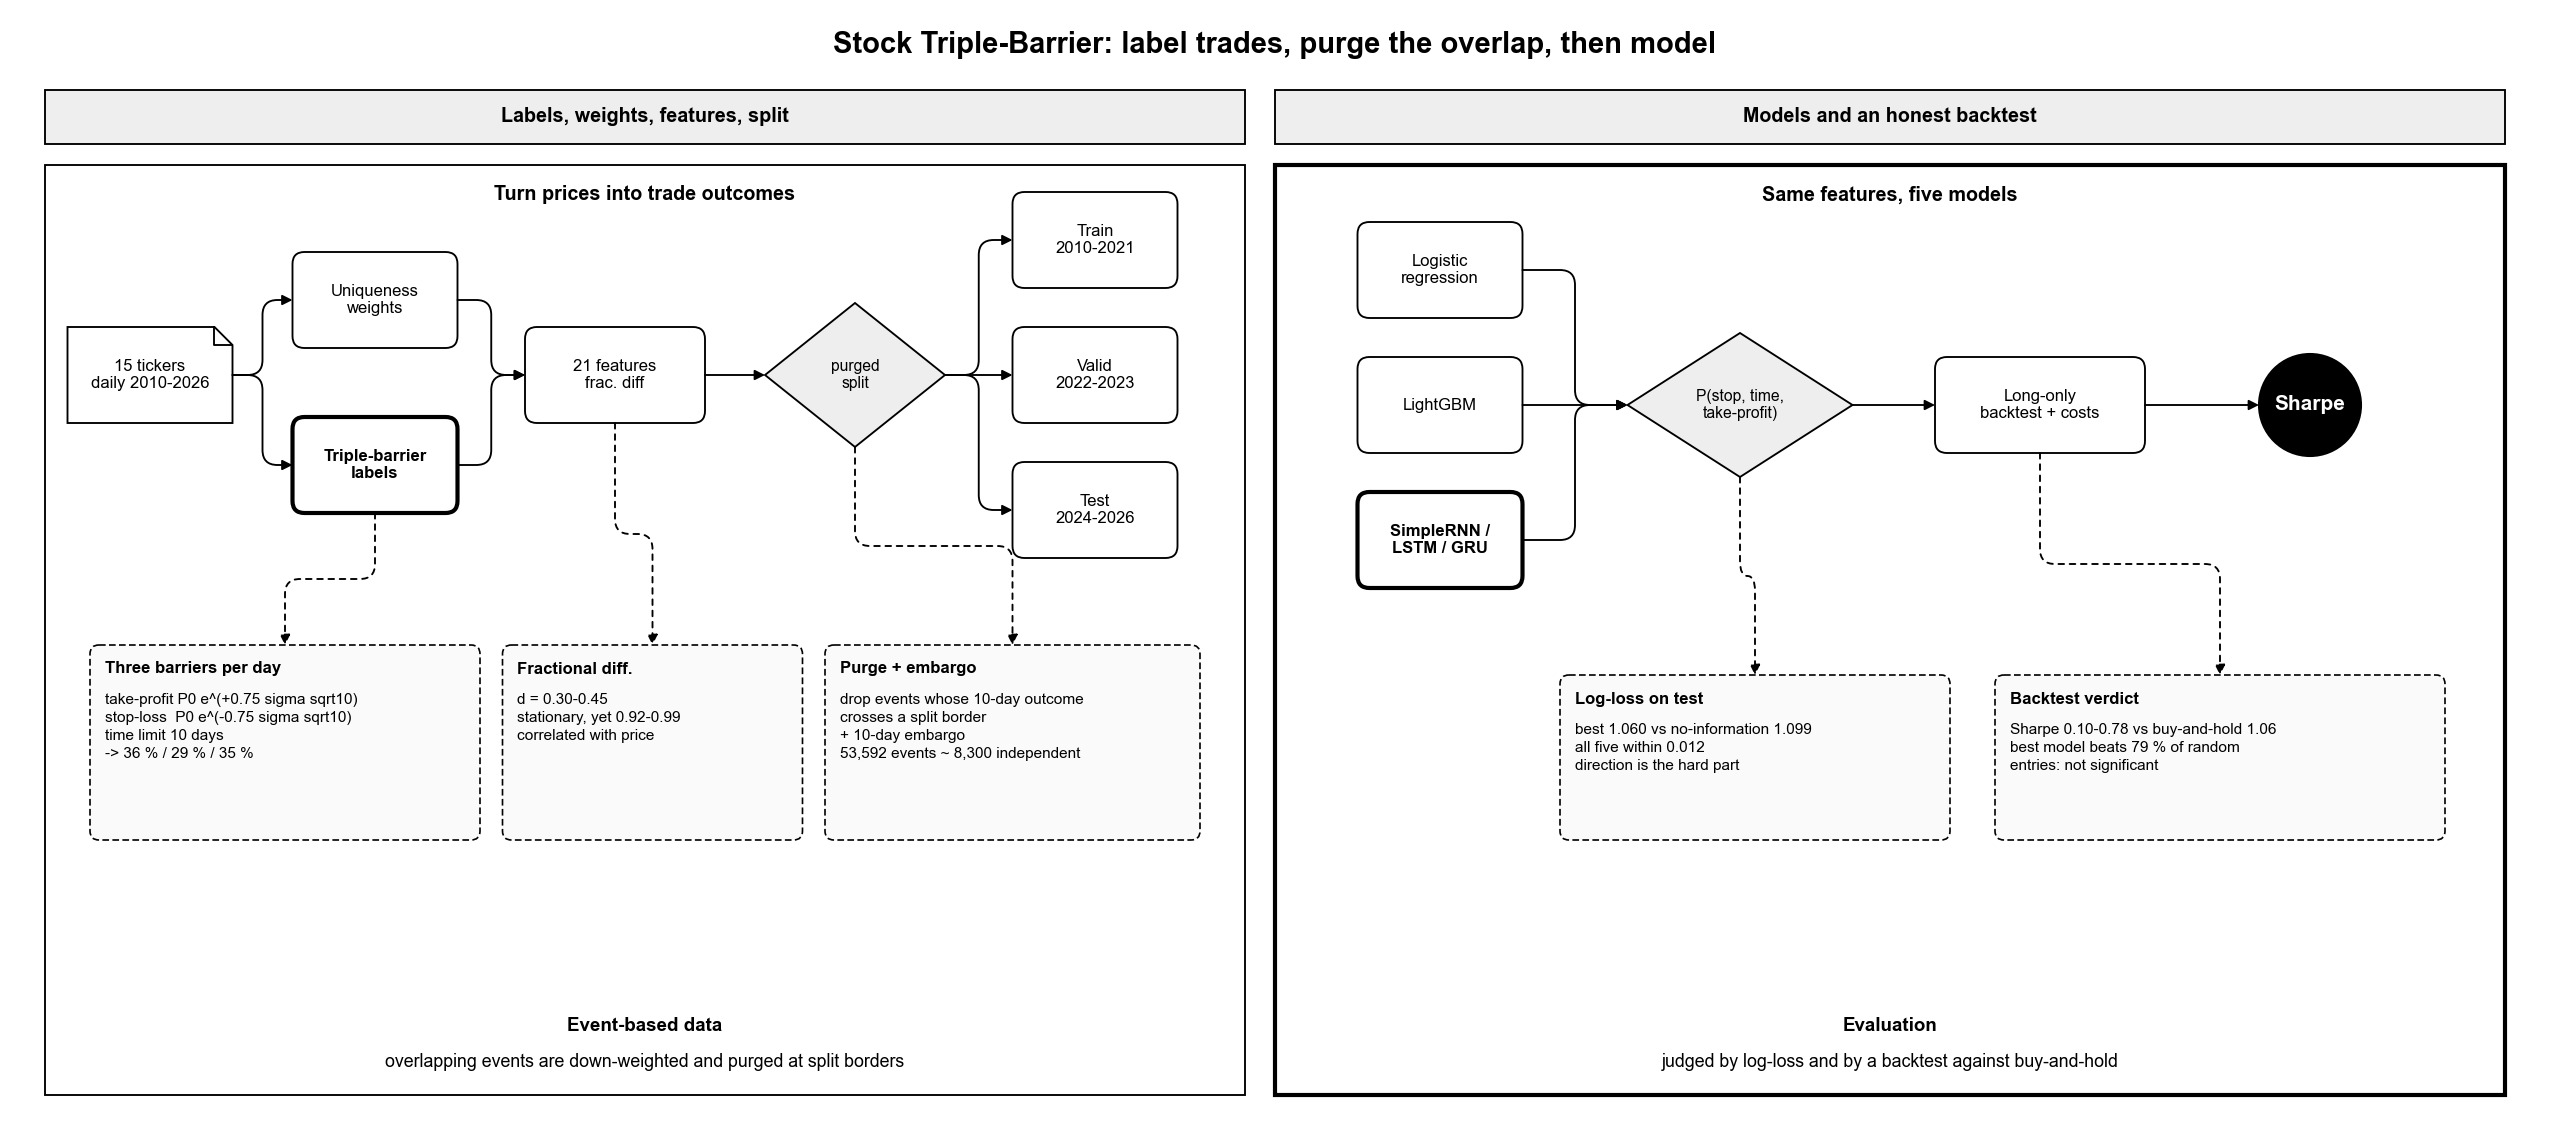

- **Problem** → most "stock prediction" notebooks predict tomorrow's price and report R² ≈ 0.99, yet copying yesterday's price scores the same: it looks smart and tells a trader nothing
- **Why this repo** → ask the question a trader actually has, *"if I buy today, do I hit my take-profit, my stop-loss, or run out of time?"*, and test it without leaking the future
- **Real-world use** → a sanity check before trusting any trading signal: label trades by outcome, purge overlapping samples, and compare against buy-and-hold and random entries

In [1]:
# ---------------------------------------------------------------- Imports
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import r2_score
from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller

from src.config import TICKERS, MARKET, START, END, PRICE_COLOR
from src.data import download_prices
from src.plotting import set_style, savefig

# ---------------------------------------------------------------- Global constants
EXAMPLE = "AAPL"                  # ticker used for single-stock illustrations
ACF_LAGS = 40
TEST_SHARE = 0.2                  # last 20 % of days as "test" in the price-level trap demo (as in my first version)
ALPHA = 0.05                      # significance level for statistical tests

set_style()

# [1/8] Download prices
> **Objective:** <u>download</u> adjusted daily prices once and cache them in `data/raw/prices.parquet` (git-ignored).
> `END` is fixed, so re-running gives the same data (Yahoo can still revise adjusted prices after new splits or dividends).

In [2]:
prices = download_prices()
close = prices.pivot(index="date", columns="ticker", values="close")

In [3]:
print(f"{len(prices):,} rows | {prices.ticker.nunique()} tickers | {prices.date.min().date()} to {prices.date.max().date()}")
prices.head()

58,253 rows | 15 tickers | 2010-01-04 to 2026-11-11


,date,ticker,open,high,low,close,volume
0,2010-01-04,AAPL,6.383611,6.415615,6.352206,6.400959,493729600.0
1,2010-01-05,AAPL,6.418607,6.448217,6.378228,6.412026,601904800.0
2,2010-01-06,AAPL,6.412025,6.437448,6.303453,6.310033,552160000.0
3,2010-01-07,AAPL,6.333365,6.340843,6.252609,6.298370,477131200.0
4,2010-01-08,AAPL,6.289995,6.340842,6.252908,6.340243,447610800.0


# [2/8] Data health
> **Question:** are there missing days, gaps or impossible values?

In [4]:
health = prices.groupby("ticker").agg(
    first_day=("date", "min"), last_day=("date", "max"), trading_days=("date", "size"),
    missing_close=("close", lambda s: s.isna().sum()),
    zero_volume_days=("volume", lambda s: (s == 0).sum()),
    non_positive_price=("close", lambda s: (s <= 0).sum()),
)
largest_moves = (np.log(close).diff().abs().max().sort_values(ascending=False) * 100)

In [5]:
health

,first_day,last_day,trading_days,missing_close,zero_volume_days,non_positive_price
ticker,,,,,,
AAPL,2010-01-04,2026-11-11,4241,0,0,0
ADBE,2010-01-04,2026-11-11,4241,0,0,0
AMD,2010-01-04,2026-11-11,4241,0,1,0
AMZN,2010-01-04,2026-11-11,4241,0,0,0
CRM,2010-01-04,2026-11-11,4241,0,0,0
CRWD,2019-06-12,2026-11-11,1866,0,0,0
GOOGL,2010-01-04,2026-11-11,4241,0,0,0
IBM,2010-01-04,2026-11-11,4241,0,0,0
INTC,2010-01-04,2026-11-11,4241,0,0,0


In [6]:
largest_moves.round(1).rename("largest |daily log return| %").head(6)

ticker
AMD     42.1
INTC    33.7
XYZ     33.6
IBM     29.0
PYPL    28.2
NVDA    26.1
Name: largest |daily log return| %, dtype: float64

**Answer:** the data is clean: no missing closes and no zero or negative prices (one day with zero volume).
Four stocks start later because they listed later: `TSLA` (2010-06), `PYPL` (2015-07), `XYZ` (2015-11, ticker `SQ` until 2025)
and `CRWD` (2019-06). The largest daily moves (up to about 40 %) are real earnings or market shocks, not errors, so nothing is removed.

# [3/8] Prices over time
> **Objective:** <u>compare</u> stocks on one scale: growth of \$1 invested at each stock's first day.

In [7]:
growth = close.apply(lambda s: s / s.dropna().iloc[0])
final_growth = growth.ffill().iloc[-1].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 6))
for t in growth.columns:
    lw, c = (2.2, "#dc2626") if t == MARKET else (1, None)
    ax.plot(growth.index, growth[t], lw=lw, color=c, label=t)
ax.set(yscale="log", ylabel="growth of $1 (log scale)", title="Growth of $1 since each stock's first day")
ax.legend(ncol=5, fontsize=8, loc="upper left")
savefig(fig, "01_growth")
plt.close(fig)

In [8]:
final_growth.round(1).rename("growth of $1")

ticker
NVDA     410.9
TSLA     245.4
AMD       57.0
AAPL      55.6
AMZN      39.8
MSFT      22.7
GOOGL     18.9
CRWD      15.8
CRM       11.9
SPY        9.0
XYZ        6.6
ADBE       6.4
INTC       4.6
IBM        3.5
PYPL       1.6
Name: growth of $1, dtype: float64

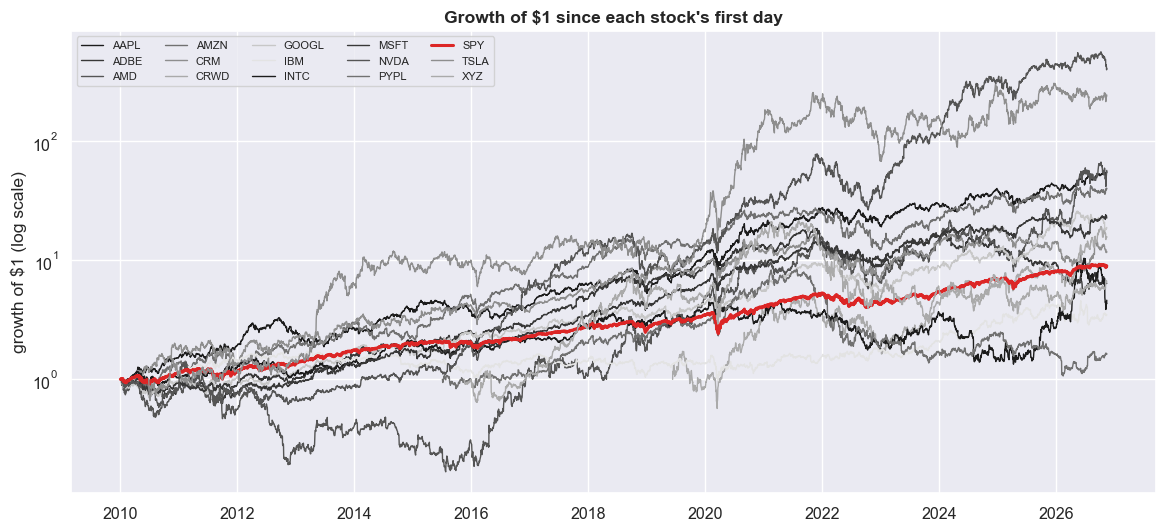

In [9]:
fig

**Answer:** growth ranges from ×411 (`NVDA`) and ×245 (`TSLA`) down to ×1.6 (`PYPL`); the market (`SPY`) grew ×9. (!) This universe was picked **today** and is
dominated by famous winners: that is **survivorship / selection bias**, and it flatters any long-only strategy. The backtest in
notebook 05 therefore compares against buy-and-hold of the **same** stocks and against random entries.

# [4/8] Returns: distribution and fat tails
> **Question:** are daily returns normally distributed?
>
> **Formulas:** log return $r_t = \ln\frac{P_t}{P_{t-1}}$ (additive over time) ·
> excess kurtosis $= \frac{1}{n}\sum\left(\frac{r_t - \bar{r}}{s}\right)^4 - 3$ (0 for a normal distribution) ·
> Jarque-Bera $JB = \frac{n}{6}\left(S^2 + \frac{K^2}{4}\right)$, $H_0$: returns are normal.

In [10]:
returns = np.log(close).diff()
moments = pd.DataFrame({
    "mean_daily_%": returns.mean() * 100,
    "std_daily_%": returns.std() * 100,
    "skew": returns.skew(),
    "excess_kurtosis": returns.kurt(),
    "jarque_bera_p": returns.apply(lambda s: stats.jarque_bera(s.dropna()).pvalue),
}).sort_values("std_daily_%", ascending=False)

r = returns[EXAMPLE].dropna()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.histplot(r, bins=150, stat="density", color=PRICE_COLOR, ax=axes[0], label="observed")
x = np.linspace(r.min(), r.max(), 400)
axes[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), color="#dc2626", lw=2, label="normal, same mean & std")
axes[0].set(xlim=(-0.1, 0.1), title=f"{EXAMPLE} daily log returns", xlabel="log return")
axes[0].legend()
stats.probplot(r, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color=PRICE_COLOR, markersize=3)
axes[1].get_lines()[1].set(color="#dc2626")
axes[1].set_title(f"{EXAMPLE} Q-Q plot vs normal")
savefig(fig, "01_returns_distribution")
plt.close(fig)

In [11]:
moments.round(3)

,mean_daily_%,std_daily_%,skew,excess_kurtosis,jarque_bera_p
ticker,,,,,
TSLA,0.134,3.592,-0.011,4.741,0.0
XYZ,0.068,3.583,-0.541,6.898,0.0
AMD,0.095,3.571,0.264,8.605,0.0
CRWD,0.148,3.551,0.018,2.787,0.0
NVDA,0.142,2.843,0.164,6.732,0.0
INTC,0.036,2.501,-0.735,21.349,0.0
PYPL,0.017,2.449,-0.951,13.279,0.0
CRM,0.058,2.307,0.230,9.909,0.0
AMZN,0.087,2.070,0.105,6.058,0.0


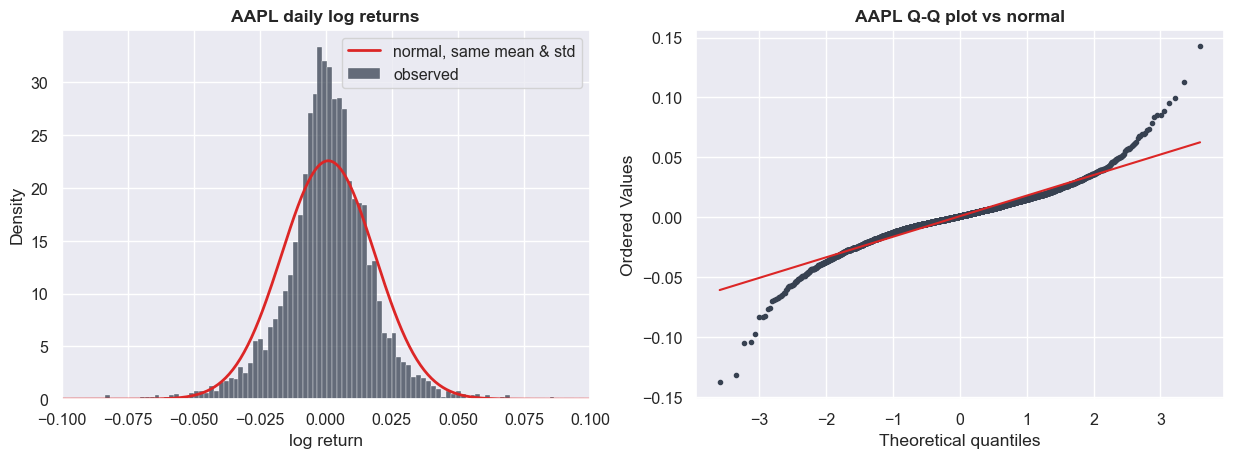

In [12]:
fig

**Answer:** no. Every stock has positive excess kurtosis (fat tails) and Jarque-Bera rejects normality with p ≈ 0.
Extreme days happen far more often than a normal distribution predicts (the Q-Q plot bends away at both ends).
→ Barriers should scale with each stock's **own volatility**, and a fixed percentage threshold would mean very different
things for `IBM` (≈ 1.6 % daily std) and `TSLA` (≈ 3.6 %).

# [5/8] Stationarity: price vs return
> **Question:** do prices and returns have a stable mean and variance over time?
>
> **Augmented Dickey-Fuller test:** $\Delta y_t = \alpha + \gamma\, y_{t-1} + \sum_{i} \beta_i\, \Delta y_{t-i} + \varepsilon_t$,
> $H_0$: $\gamma = 0$ (unit root, non-stationary). p < 0.05 → stationary.

In [13]:
adf = pd.DataFrame({
    "adf_p_log_price": np.log(close).apply(lambda s: adfuller(s.dropna(), maxlag=1, autolag=None)[1]),
    "adf_p_log_return": returns.apply(lambda s: adfuller(s.dropna(), maxlag=1, autolag=None)[1]),
})
adf["price_stationary"] = adf["adf_p_log_price"] < ALPHA
adf["return_stationary"] = adf["adf_p_log_return"] < ALPHA

In [14]:
adf.round(4)

,adf_p_log_price,adf_p_log_return,price_stationary,return_stationary
ticker,,,,
AAPL,0.8684,0.0,False,True
ADBE,0.6416,0.0,False,True
AMD,0.9884,0.0,False,True
AMZN,0.7410,0.0,False,True
CRM,0.3198,0.0,False,True
CRWD,0.8267,0.0,False,True
GOOGL,0.9591,0.0,False,True
IBM,0.7536,0.0,False,True
INTC,0.4598,0.0,False,True


**Answer:** log prices are **non-stationary** for every stock (ADF p between 0.31 and 0.99, unit root not rejected), while
returns are stationary for all of them (p ≈ 0). Models trained on price levels learn "the price is near where it was", which does not transfer to new price
ranges. → Features in this project are built from **returns and ratios**, plus a *fractionally* differenced price that keeps
some memory while being stationary (notebook 03).

# [6/8] Autocorrelation and volatility clustering
> **Question:** do past returns predict future returns? Does past volatility predict future volatility?
>
> **Autocorrelation at lag k:** $\rho_k = \frac{\sum_t (r_t - \bar r)(r_{t-k} - \bar r)}{\sum_t (r_t - \bar r)^2}$;
> the band is the 95 % confidence interval of zero autocorrelation.

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
plot_acf(r, lags=ACF_LAGS, ax=axes[0], color=PRICE_COLOR, vlines_kwargs={"colors": PRICE_COLOR})
axes[0].set(title=f"{EXAMPLE}: ACF of returns", ylim=(-0.15, 0.3))
plot_acf(r ** 2, lags=ACF_LAGS, ax=axes[1], color="#dc2626", vlines_kwargs={"colors": "#dc2626"})
axes[1].set(title=f"{EXAMPLE}: ACF of squared returns (volatility)", ylim=(-0.15, 0.3))
savefig(fig, "01_acf")
plt.close(fig)

acf_summary = pd.DataFrame({
    "acf1_returns": returns.apply(lambda s: s.autocorr(1)),
    "acf1_squared_returns": (returns ** 2).apply(lambda s: s.autocorr(1)),
})

In [16]:
acf_summary.round(3)

,acf1_returns,acf1_squared_returns
ticker,,
AAPL,-0.031,0.218
ADBE,-0.068,0.163
AMD,-0.023,0.096
AMZN,-0.013,0.110
CRM,-0.020,0.078
CRWD,0.045,0.155
GOOGL,-0.026,0.089
IBM,-0.006,0.038
INTC,-0.028,0.138


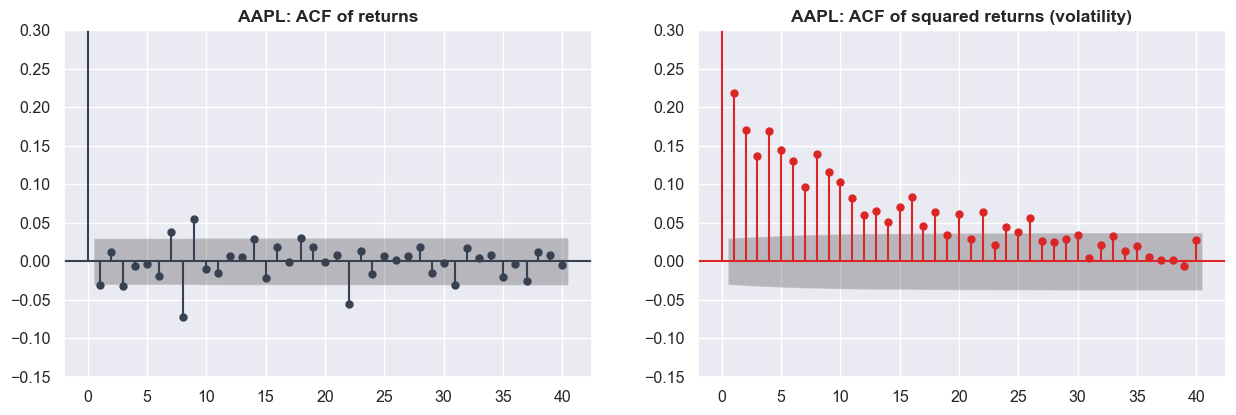

In [17]:
fig

**Answer:** returns have almost **no** autocorrelation (lag-1 between −0.10 and 0.05), so tomorrow's direction is very hard to predict
from past returns alone. Squared returns are positively autocorrelated for every stock (0.04 for `IBM` up to 0.40 for `SPY`):
**volatility clusters** (calm and turbulent periods persist).
→ Volatility is predictable, so barrier widths based on recent volatility are sensible; direction is where the difficulty lies.

# [7/8] The price-level trap
## 7.1 Naive "tomorrow = today" forecast
> **Question:** how good is R² ≈ 0.99 on scaled prices, really?
>
> **Formula:** $R^2 = 1 - \frac{\sum (y_t - \hat y_t)^2}{\sum (y_t - \bar y)^2}$. A naive forecast $\hat P_t = P_{t-1}$ needs no model at all.

In [18]:
naive = pd.DataFrame({
    "r2_price_naive": close.apply(lambda s: r2_score(s.dropna()[1:], s.dropna().shift(1)[1:])),
    "r2_return_naive": returns.apply(lambda s: r2_score(s.dropna()[1:], s.dropna().shift(1)[1:])),
})

In [19]:
naive.round(4)

,r2_price_naive,r2_return_naive
ticker,,
AAPL,0.9994,-1.0610
ADBE,0.9987,-1.1368
AMD,0.9973,-1.0457
AMZN,0.9990,-1.0264
CRM,0.9982,-1.0395
CRWD,0.9966,-0.9196
GOOGL,0.9992,-1.0509
IBM,0.9974,-1.0119
INTC,0.9947,-1.0534


**Answer:** copying yesterday's price gives **R² between 0.995 and 0.9996** on price levels, without learning anything, because
the variance of a trending price is huge compared with one day's change. On **returns** the same naive forecast scores about −1.
→ My first version's R² ≈ 0.99 mostly measured this effect; R² on prices is not evidence of forecasting skill.

## 7.2 Scaling before splitting
> **Question:** what goes wrong when `MinMaxScaler` is fitted on the full series before the train/test split (as in my first version)?

In [20]:
s = close[EXAMPLE].dropna()
split = int(len(s) * (1 - TEST_SHARE))
leaky = MinMaxScaler().fit(s.to_frame())                     # fitted on train + test
honest = MinMaxScaler().fit(s.iloc[:split].to_frame())       # fitted on train only
scaled_test = pd.DataFrame({
    "leaky_scaler": leaky.transform(s.iloc[split:].to_frame()).ravel(),
    "train_only_scaler": honest.transform(s.iloc[split:].to_frame()).ravel(),
})

In [21]:
scaled_test.describe().loc[["min", "max"]].round(2)

,leaky_scaler,train_only_scaler
min,0.45,0.88
max,1.00,1.96


**Answer:** with the leaky scaler the test prices stay inside [0, 1] (0.45 to 1.00), because the scaler already saw the test period's
maximum. Fitted on training data only, test values reach 1.96 — the model would face prices it has never seen. The leaky version
quietly tells the model the future price range. → In this project every scaler is fitted on the **training period only**.

# [8/8] Summary & decisions
| Finding | Decision |
|---|---|
| Clean data; three stocks listed later | keep all; each stock contributes from its first day |
| Universe picked in hindsight (survivorship bias) | compare strategies with buy-and-hold of the same stocks and random entries |
| Fat tails, very different volatility per stock | barriers scaled by each stock's own recent volatility |
| Prices non-stationary, returns stationary | features from returns / ratios + fractionally differenced price |
| Returns barely autocorrelated, volatility clusters | volatility-based barriers; expect modest directional skill |
| R² on prices is ≈ 0.999 for a naive forecast | predict **triple-barrier outcomes** instead of price levels |
| Scaler fitted before splitting leaks the future | fit every transformation on the training period only |